# Week 5: Census Age Exploratory Data Analysis

## Niagara Succession Signal

**Purpose:** Explore demographic age patterns across Niagara and its 12 municipalities using the previously cleaned Statistics Canada Census age dataset.

### Research questions
1. How did Niagara's population age structure change between 2016 and 2021?
2. How does the population aged 65 and over vary across Niagara's municipalities?
3. How did median age change across municipalities between the two census years?

### Scope and interpretation
This notebook performs exploratory data analysis (EDA), not data cleaning or succession-risk modelling. It uses the Week 4 cleaned dataset and does not modify the raw data.

**Important limitation:** Population age is not business-owner age. The results provide demographic context for succession research but cannot independently establish business succession risk.

### Method
- Use `Census year (2)` to identify the census observation year.
- Use non-overlapping age bands when comparing age structure.
- Use the existing `65 years and over` category directly instead of adding its subcategories.
- Exclude the regional total (`Niagara`) when comparing municipalities to avoid treating it as another municipality.


## 1. Load libraries and data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("../../data/interim/census_age_niagara_cleaned.csv")
FIGURE_DIR = Path("../../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

YEAR = "Census year (2)"
GEO = "GEO"
AGE = "Age (in single years), average age and median age (128)"
POP = "Gender (3a):Total - Gender[1]"
MEN = "Gender (3a):Men+[2]"
WOMEN = "Gender (3a):Women+[3]"

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Census years: {sorted(df[YEAR].unique())}")
print(f"Geographies: {df[GEO].nunique()}")
display(df.head())


Rows: 3,328
Columns: 12
Census years: [np.int64(2016), np.int64(2021)]
Geographies: 13


,REF_DATE,GEO,DGUID,Census year (2),"Age (in single years), average age and median age (128)",Coordinate,Gender (3a):Total - Gender[1],Symbol,Gender (3a):Men+[2],Symbol.1,Gender (3a):Women+[3],Symbol.2
0,2021,Niagara,2021A00033526,2021,Total - Age,2416.1.1,477940.0,NaN,232715.0,NaN,245225.0,NaN
1,2021,Niagara,2021A00033526,2021,0 to 14 years,2416.1.2,70600.0,NaN,36280.0,NaN,34320.0,NaN
2,2021,Niagara,2021A00033526,2021,0 to 4 years,2416.1.3,21830.0,NaN,11285.0,NaN,10545.0,NaN
3,2021,Niagara,2021A00033526,2021,Under 1 year,2416.1.4,4075.0,NaN,2095.0,NaN,1980.0,NaN
4,2021,Niagara,2021A00033526,2021,1,2416.1.5,4220.0,NaN,2190.0,NaN,2030.0,NaN


## 2. Validate the analysis inputs

In [2]:
# Check expected columns and basic data integrity.
required_columns = [YEAR, GEO, AGE, POP, MEN, WOMEN]
missing_columns = [column for column in required_columns if column not in df.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

assert set(df[YEAR].unique()) == {2016, 2021}, "Unexpected census years."
assert df[POP].notna().all(), "Population totals contain missing values."
assert not df.duplicated().any(), "Exact duplicate rows found."

# Confirm each geography has one total-population record per census year.
totals = df.loc[df[AGE].eq("Total - Age")].copy()
total_counts = totals.groupby([GEO, YEAR]).size()
assert total_counts.eq(1).all(), "Some geography-year combinations have duplicate or missing total rows."

print("Required columns: present")
print("Census years: 2016 and 2021")
print("Missing population values:", int(df[POP].isna().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Total-population records:", len(totals))
print("REF_DATE values:", sorted(df["REF_DATE"].unique()))
print("The observation year is taken from Census year (2), not REF_DATE.")


Required columns: present
Census years: 2016 and 2021
Missing population values: 0
Exact duplicate rows: 0
Total-population records: 26
REF_DATE values: [np.int64(2021)]
The observation year is taken from Census year (2), not REF_DATE.


## 3. Niagara population change

Compare the regional total across the two census years. The regional total is used here only for the overall Niagara comparison; it will be excluded from municipality rankings.


In [3]:
niagara_totals = totals.loc[totals[GEO].eq("Niagara"), [YEAR, POP]].sort_values(YEAR)
display(niagara_totals)

if len(niagara_totals) == 2:
    population_2016 = float(niagara_totals.loc[niagara_totals[YEAR].eq(2016), POP].iloc[0])
    population_2021 = float(niagara_totals.loc[niagara_totals[YEAR].eq(2021), POP].iloc[0])
    absolute_change = population_2021 - population_2016
    percent_change = absolute_change / population_2016 * 100

    print(f"Absolute population change: {absolute_change:,.0f}")
    print(f"Percentage population change: {percent_change:.2f}%")


,Census year (2),Gender (3a):Total - Gender[1]
128,2016,447890.0
0,2021,477940.0


Absolute population change: 30,050
Percentage population change: 6.71%


In [4]:
import sys
print(sys.executable)

c:\Program Files\Python313\python.exe


## 4. Age structure in Niagara

We compare broad, non-overlapping age groups. Each group is calculated from the existing single-year age rows so that overlapping parent and child categories are not added together.


In [12]:
# Convert single-year age labels to numeric ages.
age_numeric = pd.to_numeric(df[AGE], errors="coerce")

# Include Niagara's single-year ages and special age categories.
niagara_people = df.loc[
    df[GEO].eq("Niagara"),
    [YEAR, AGE, POP]
].copy()

niagara_people["age"] = pd.to_numeric(
    niagara_people[AGE],
    errors="coerce"
)

# Assign numeric single-year ages to non-overlapping groups.
age_bins = [-1, 14, 24, 34, 44, 54, 64, 74, 84, float("inf")]

age_labels = [
    "0–14", "15–24", "25–34", "35–44", "45–54",
    "55–64", "65–74", "75–84", "85+"
]

# Keep only numeric single-year ages for this grouping.
# Special categories are handled separately below.
numeric_people = niagara_people.loc[
    niagara_people["age"].notna()
].copy()

numeric_people["age_group"] = pd.cut(
    numeric_people["age"],
    bins=age_bins,
    labels=age_labels
)

# Map special categories into the appropriate groups.
special_ages = niagara_people.loc[
    niagara_people["age"].isna()
].copy()

special_age_map = {
    "Under 1 year": "0–14",
    "100 years and over": "85+",
}

special_ages["age_group"] = special_ages[AGE].map(special_age_map)

# Combine numeric ages and mapped special categories.
niagara_people = pd.concat(
    [
        numeric_people[[YEAR, AGE, POP, "age_group"]],
        special_ages.loc[
            special_ages["age_group"].notna(),
            [YEAR, AGE, POP, "age_group"]
        ],
    ],
    ignore_index=True
)

# Aggregate population by year and non-overlapping age group.
age_structure = (
    niagara_people.groupby(
        [YEAR, "age_group"],
        observed=False
    )[POP]
    .sum()
    .reset_index()
)

# Calculate percentages using the published Niagara population totals.
niagara_denominators = totals.loc[
    totals[GEO].eq("Niagara"),
    [YEAR, POP]
].rename(columns={POP: "regional_population"})

age_structure = age_structure.merge(
    niagara_denominators,
    on=YEAR,
    how="left"
)

age_structure["percentage"] = (
    age_structure[POP] /
    age_structure["regional_population"] * 100
)

display(age_structure)

,Census year (2),age_group,Gender (3a):Total - Gender[1],regional_population,percentage
0,2016,0–14,66760.0,447890.0,14.905446
1,2016,15–24,53870.0,447890.0,12.027507
2,2016,25–34,49125.0,447890.0,10.968095
3,2016,35–44,50100.0,447890.0,11.185782
4,2016,45–54,64470.0,447890.0,14.394159
5,2016,55–64,67710.0,447890.0,15.117551
6,2016,65–74,52800.0,447890.0,11.788609
7,2016,75–84,29000.0,447890.0,6.474804
8,2016,85+,14030.0,447890.0,3.132466
9,2021,0–14,70595.0,477940.0,14.770683


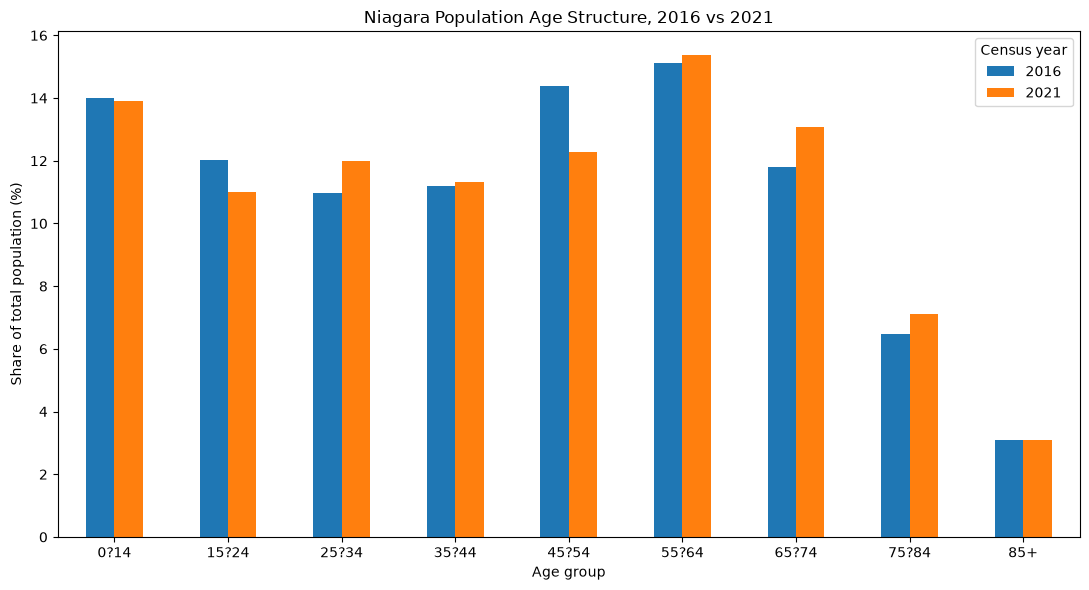

In [6]:
age_pivot = age_structure.pivot(
    index="age_group", columns=YEAR, values="percentage"
).reindex(age_labels)

ax = age_pivot.plot(kind="bar", figsize=(11, 6))
ax.set_title("Niagara Population Age Structure, 2016 vs 2021")
ax.set_xlabel("Age group")
ax.set_ylabel("Share of total population (%)")
ax.legend(title="Census year")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "niagara_age_structure_2016_2021.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Population aged 65 and over by municipality

The published `65 years and over` category is used directly. The Niagara regional total is excluded from the municipality comparison.


In [13]:
# Check the age-group percentages for each census year.
age_group_check = (
    age_structure.groupby(YEAR)["percentage"]
    .sum()
    .rename("age_group_percentage_total")
)

display(age_group_check)

# Compare grouped population counts with published regional totals.
age_population_check = (
    age_structure.groupby(YEAR)[POP]
    .sum()
    .rename("grouped_age_population")
    .to_frame()
    .join(
        niagara_denominators.set_index(YEAR)["regional_population"]
    )
)

age_population_check["difference"] = (
    age_population_check["grouped_age_population"]
    - age_population_check["regional_population"]
)

display(age_population_check)

Census year (2)
2016     99.994418
2021    100.006277
Name: age_group_percentage_total, dtype: float64

,grouped_age_population,regional_population,difference
Census year (2),,,
2016,447865.0,447890.0,-25.0
2021,477970.0,477940.0,30.0


In [7]:
municipalities = sorted(g for g in df[GEO].dropna().unique() if g != "Niagara")

population_totals = totals.loc[
    totals[GEO].isin(municipalities), [GEO, YEAR, POP]
].rename(columns={POP: "total_population"})

older_population = df.loc[
    df[GEO].isin(municipalities) & df[AGE].eq("65 years and over"),
    [GEO, YEAR, POP]
].rename(columns={POP: "population_65_plus"})

older_share = population_totals.merge(
    older_population, on=[GEO, YEAR], how="left", validate="one_to_one"
)
assert older_share["population_65_plus"].notna().all(), "Missing 65+ values."

older_share["share_65_plus_pct"] = (
    older_share["population_65_plus"] / older_share["total_population"] * 100
)

older_2021 = older_share.loc[older_share[YEAR].eq(2021)].sort_values(
    "share_65_plus_pct", ascending=False
)
display(older_2021)


,GEO,Census year (2),total_population,population_65_plus,share_65_plus_pct
16,Niagara-on-the-Lake,2021,19090.0,6905.0,36.170770
0,Fort Erie,2021,32900.0,8970.0,27.264438
8,Pelham,2021,18195.0,4960.0,27.260236
2,Port Colborne,2021,20035.0,5375.0,26.828051
18,St. Catharines,2021,136800.0,31865.0,23.293129
10,Welland,2021,55750.0,12840.0,23.031390
20,Lincoln,2021,25715.0,5740.0,22.321602
14,Niagara Falls,2021,94415.0,20665.0,21.887412
22,Grimsby,2021,28885.0,6160.0,21.325948
4,Wainfleet,2021,6885.0,1445.0,20.987654


In [14]:
# Inspect all age labels that could not be converted to numeric ages.
special_age_labels = (
    df.loc[df[GEO].eq("Niagara"), AGE]
    .drop_duplicates()
    .loc[lambda s: pd.to_numeric(s, errors="coerce").isna()]
    .sort_values()
)

print("Non-numeric age labels in the Niagara data:")
display(special_age_labels.to_frame(name=AGE))

Non-numeric age labels in the Niagara data:


,"Age (in single years), average age and median age (128)"
1,0 to 14 years
2,0 to 4 years
14,10 to 14 years
125,100 years and over
21,15 to 19 years
20,15 to 64 years
27,20 to 24 years
33,25 to 29 years
39,30 to 34 years
45,35 to 39 years


In [15]:
# Inspect special age categories for Niagara in both census years.
special_labels = [
    "Under 1 year",
    "100 years and over",
    "Total - Age",
]

special_age_check = df.loc[
    df[GEO].eq("Niagara")
    & df[AGE].isin(special_labels),
    [YEAR, AGE, POP],
].sort_values([YEAR, AGE])

display(special_age_check)

,Census year (2),"Age (in single years), average age and median age (128)",Gender (3a):Total - Gender[1]
253,2016,100 years and over,115.0
128,2016,Total - Age,447890.0
131,2016,Under 1 year,4055.0
125,2021,100 years and over,145.0
0,2021,Total - Age,477940.0
3,2021,Under 1 year,4075.0


In [17]:
for year in sorted(df[YEAR].dropna().unique()):
    niagara = df.loc[
        df[GEO].eq("Niagara") & df[YEAR].eq(year)
    ].copy()

    numeric_age = pd.to_numeric(niagara[AGE], errors="coerce")

    single_year_total = niagara.loc[numeric_age.notna(), POP].sum()
    under_one = niagara.loc[niagara[AGE].eq("Under 1 year"), POP].sum()
    hundred_plus = niagara.loc[niagara[AGE].eq("100 years and over"), POP].sum()
    published_total = niagara.loc[niagara[AGE].eq("Total - Age"), POP].sum()

    detailed_total = single_year_total + under_one + hundred_plus

    print(f"\nYear: {year}")
    print(f"Numeric single-year ages: {single_year_total:,.0f}")
    print(f"Under 1 year: {under_one:,.0f}")
    print(f"100 years and over: {hundred_plus:,.0f}")
    print(f"Combined detailed total: {detailed_total:,.0f}")
    print(f"Published total: {published_total:,.0f}")
    print(f"Difference: {detailed_total - published_total:,.0f}")


Year: 2016
Numeric single-year ages: 443,695
Under 1 year: 4,055
100 years and over: 115
Combined detailed total: 447,865
Published total: 447,890
Difference: -25

Year: 2021
Numeric single-year ages: 473,750
Under 1 year: 4,075
100 years and over: 145
Combined detailed total: 477,970
Published total: 477,940
Difference: 30


In [19]:
for year in sorted(df[YEAR].dropna().unique()):
    niagara = df.loc[
        df[GEO].eq("Niagara") & df[YEAR].eq(year)
    ].copy()

    numeric_age = pd.to_numeric(niagara[AGE], errors="coerce")
    numeric_rows = niagara.loc[numeric_age.notna()]

    print(f"\nCensus year: {year}")
    print("Missing population counts:", numeric_rows[POP].isna().sum())
    print("Zero population counts:", numeric_rows[POP].eq(0).sum())
    print("Negative population counts:", numeric_rows[POP].lt(0).sum())
    print("Numeric age range:", numeric_age.min(), "to", numeric_age.max())


Census year: 2016
Missing population counts: 0
Zero population counts: 0
Negative population counts: 0
Numeric age range: 1.0 to 99.0

Census year: 2021
Missing population counts: 0
Zero population counts: 0
Negative population counts: 0
Numeric age range: 1.0 to 99.0


In [20]:
# Compare the age totals with the published regional total.
for year in [2016, 2021]:
    niagara = df.loc[
        df[GEO].eq("Niagara") & df[YEAR].eq(year)
    ]

    print(f"\nCensus year: {year}")

    print(
        niagara.loc[
            niagara[AGE].isin(
                ["Total - Age", "Under 1 year", "100 years and over"]
            ),
            [AGE, POP]
        ].to_string(index=False)
    )

    print(
        "Sum of ages 1–99:",
        niagara.loc[
            pd.to_numeric(niagara[AGE], errors="coerce").notna(),
            POP
        ].sum()
    )


Census year: 2016
Age (in single years), average age and median age (128)  Gender (3a):Total - Gender[1]
                                            Total - Age                       447890.0
                                           Under 1 year                         4055.0
                                     100 years and over                          115.0
Sum of ages 1–99: 443695.0

Census year: 2021
Age (in single years), average age and median age (128)  Gender (3a):Total - Gender[1]
                                            Total - Age                       477940.0
                                           Under 1 year                         4075.0
                                     100 years and over                          145.0
Sum of ages 1–99: 473750.0


In [21]:
# Compare the raw and cleaned age counts.
from pathlib import Path
import pandas as pd

print("Current cleaned dataset:", df.shape)

print("\nPublished totals in the cleaned dataset:")
display(
    df.loc[
        df[GEO].eq("Niagara")
        & df[AGE].eq("Total - Age"),
        [YEAR, AGE, POP]
    ].sort_values(YEAR)
)

Current cleaned dataset: (3328, 12)

Published totals in the cleaned dataset:


,Census year (2),"Age (in single years), average age and median age (128)",Gender (3a):Total - Gender[1]
128,2016,Total - Age,447890.0
0,2021,Total - Age,477940.0


In [25]:

from pathlib import Path

cwd = Path.cwd()

print("Notebook working directory:")
print(cwd)

print("\nChecking current and parent directories:")

for folder in [cwd, *cwd.parents]:
    print(f"\nChecking: {folder}")
    print("  data folder:", (folder / "data").exists())
    print(
        "  cleaned file:",
        (folder / "data/interim/census_age_niagara_cleaned.csv").exists()
    )

Notebook working directory:
c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5\notebooks\03_eda

Checking current and parent directories:

Checking: c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5\notebooks\03_eda
  data folder: False
  cleaned file: False

Checking: c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5\notebooks
  data folder: False
  cleaned file: False

Checking: c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5
  data folder: True
  cleaned file: True

Checking: c:\Users\Home PC\Desktop\Founder's Challenge
  data folder: False
  cleaned file: False

Checking: c:\Users\Home PC\Desktop
  data folder: False
  cleaned file: False

Checking: c:\Users\Home PC
  data folder: False
  cleaned file: False

Checking: c:\Users
  data folder: False
  cleaned file: False

Checking: c:\
  data folder: False
  cleaned file: False


In [26]:
from pathlib import Path

project_root = Path.cwd().parents[1]

print("Project root:", project_root)

print("\nCSV files in data/raw:")
raw_dir = project_root / "data" / "raw"

if raw_dir.exists():
    for file in raw_dir.rglob("*.csv"):
        print(file.relative_to(project_root))
else:
    print("The data/raw directory does not exist.")

print("\nCleaned dataset:")
print(project_root / "data" / "interim" / "census_age_niagara_cleaned.csv")

Project root: c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5

CSV files in data/raw:
data\raw\33101176.csv
data\raw\33101176_MetaData.csv
data\raw\OpenData_Consolidated_NEI_Opendata_-482263215789080610.csv
data\raw\statcan\business_dynamics\33100087.csv
data\raw\statcan\business_dynamics\33100087_MetaData.csv
data\raw\statcan\business_dynamics\33100088.csv
data\raw\statcan\business_dynamics\33100088_MetaData.csv
data\raw\statcan\census\98100022_MetaData.csv
data\raw\statcan\census_demographics\9810059201-eng.csv
data\raw\statcan\census_demographics\98100592_MetaData.csv
data\raw\statcan\succession\33101196.csv
data\raw\statcan\succession\33101196_MetaData.csv
data\raw\statcan\succession\33101197.csv
data\raw\statcan\succession\33101197_MetaData.csv
data\raw\statcan\succession\33101198.csv
data\raw\statcan\succession\33101198_MetaData.csv
data\raw\statcan\succession\33101199.csv
data\raw\statcan\succession\33101199_MetaData.csv

Cleaned dataset:
c:\Users\Ho

In [27]:
from pathlib import Path

project_root = Path.cwd().parents[1]

print("Searching the entire Week 5 project for the original file...\n")

matches = [
    path
    for path in project_root.rglob("*")
    if path.is_file()
    and path.name.lower() in {
        "98100022.csv",
        "98100022-eng.csv",
        "98100022-eng.zip",
    }
]

if matches:
    for path in matches:
        print(path.relative_to(project_root))
else:
    print("Original Census CSV not found by filename.")

print("\nOther Census-related CSV files:\n")

for path in project_root.rglob("*.csv"):
    if "census" in str(path).lower() or "98100022" in path.name.lower():
        print(path.relative_to(project_root))

Searching the entire Week 5 project for the original file...

Original Census CSV not found by filename.

Other Census-related CSV files:

census_age_niagara_cleaned.csv
data\interim\census_age_niagara_cleaned.csv
data\interim\census_self_employment_niagara_cleaned.csv
data\raw\statcan\census\98100022_MetaData.csv
data\raw\statcan\census_demographics\9810059201-eng.csv
data\raw\statcan\census_demographics\98100592_MetaData.csv


In [28]:
from pathlib import Path

project_root = Path.cwd().parents[1]
raw_path = project_root / "data" / "raw" / "statcan" / "census" / "98100022.csv"

print("Original Census file exists:", raw_path.exists())
print("File path:", raw_path)

Original Census file exists: True
File path: c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5\data\raw\statcan\census\98100022.csv


In [29]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parents[1]

raw_path = (
    project_root / "data" / "raw" / "statcan" / "census" / "98100022.csv"
)
cleaned_path = (
    project_root / "data" / "interim" / "census_age_niagara_cleaned.csv"
)

raw = pd.read_csv(raw_path, low_memory=False)
cleaned = pd.read_csv(cleaned_path, low_memory=False)

print("RAW DATA SHAPE:", raw.shape)
print("CLEANED DATA SHAPE:", cleaned.shape)

print("\nRAW COLUMN NAMES:")
print(raw.columns.tolist())

print("\nCLEANED COLUMN NAMES:")
print(cleaned.columns.tolist())

RAW DATA SHAPE: (1399808, 12)
CLEANED DATA SHAPE: (3328, 12)

RAW COLUMN NAMES:
['REF_DATE', 'GEO', 'DGUID', 'Census year (2)', 'Age (in single years), average age and median age (128)', 'Coordinate', 'Gender (3a):Total - Gender[1]', 'Symbol', 'Gender (3a):Men+[2]', 'Symbol.1', 'Gender (3a):Women+[3]', 'Symbol.2']

CLEANED COLUMN NAMES:
['REF_DATE', 'GEO', 'DGUID', 'Census year (2)', 'Age (in single years), average age and median age (128)', 'Coordinate', 'Gender (3a):Total - Gender[1]', 'Symbol', 'Gender (3a):Men+[2]', 'Symbol.1', 'Gender (3a):Women+[3]', 'Symbol.2']


In [40]:
# Check detailed age categories for Niagara in each census year

niagara = cleaned[cleaned[GEO] == "Niagara"].copy()

niagara[POP] = pd.to_numeric(niagara[POP], errors="coerce")
niagara["age_label"] = niagara[AGE].astype(str).str.strip()

# Keep individual ages and special categories only
individual_ages = niagara[
    niagara["age_label"].str.fullmatch(r"\d+")
    | niagara["age_label"].isin(["Under 1 year", "100 years and over"])
].copy()

for year in [2016, 2021]:
    year_data = individual_ages[individual_ages[YEAR] == year]

    print(f"\nCensus year: {year}")
    print("Number of detailed age records:", len(year_data))
    print("Sum of detailed age counts:", int(year_data[POP].sum()))

    duplicates = year_data[
        year_data["age_label"].duplicated(keep=False)
    ]

    print("Duplicated age labels:", len(duplicates))

    if not duplicates.empty:
        print(duplicates[["age_label", POP]].to_string(index=False))

    print("Published total:")
    print(
        niagara.loc[
            (niagara[YEAR] == year)
            & (niagara["age_label"] == "Total - Age"),
            POP
        ].to_string(index=False)
    )


Census year: 2016
Number of detailed age records: 101
Sum of detailed age counts: 447865
Duplicated age labels: 0
Published total:
447890.0

Census year: 2021
Number of detailed age records: 101
Sum of detailed age counts: 477970
Duplicated age labels: 0
Published total:
477940.0


In [45]:
import pandas as pd

metadata = pd.read_csv(
    metadata_path,
    encoding="utf-8-sig",
    dtype=str,
    low_memory=False
).fillna("")

# Display cube-level information
print("CUBE TITLE")
print(metadata["Cube Title"].iloc[0])

print("\nCUBE NOTES")
print(metadata["Cube Notes"].replace("", pd.NA).dropna().to_list())

# Search all metadata fields for relevant explanations
keywords = r"round|rounded|random|confidential|suppressed|estimate|population count"

matches = metadata[
    metadata.astype(str).apply(
        lambda column: column.str.contains(
            keywords, case=False, na=False, regex=True
        )
    ).any(axis=1)
]

print("\nRELEVANT METADATA RECORDS")
print(matches.to_string(index=False, max_cols=6))

CUBE TITLE
Age (in single years), average age and median age and gender: Canada, provinces and territories, census divisions and census subdivisions

CUBE NOTES
['1', 'Dimension Definitions', 'Parent Member ID', '1', '2', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '3', '2', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '99', '2', '135', '135', '135', '135', '135', '135', '135', '135', '135', '135', '135', '135',

In [44]:
# Display the relevant metadata fields without loading the file again

print("CUBE TITLE:")
print(metadata["Cube Title"].dropna().astype(str).head(10).to_string(index=False))

print("\nCUBE NOTES:")
print(metadata["Cube Notes"].dropna().astype(str).to_string(index=False))

print("\nVARIABLE LIST:")
print(metadata["Variable List"].dropna().astype(str).to_string(index=False))

CUBE TITLE:
Age (in single years), average age and median a...
                                      Dimension ID
                                                 1
                                                 2
                                                 3
                                                 4
                                      Dimension ID
                                                 1
                                                 1
                                                 1

CUBE NOTES:
                                                1
                            Dimension Definitions
                                 Parent Member ID
                                                1
                                                2
                                                3
                                                3
                                                3
                                                3
               

In [46]:
print(metadata["Cube Notes"].dropna().head(5).to_list())

['1', 'Dimension Definitions', '', '', '']


In [42]:
from pathlib import Path

# Check the current working directory
print("Current working directory:")
print(Path.cwd())

# Search for the metadata file within the project
project_root = Path.cwd()

matches = list(project_root.rglob("*MetaData.csv"))

print("\nMetadata files found:")
for file in matches:
    print(file)

Current working directory:
c:\Users\Home PC\Desktop\Founder's Challenge\niagara-succession-signal-week5\notebooks\03_eda

Metadata files found:


In [39]:
import inspect

print(inspect.getsource(type(age_structure)))
print("\nAge-band construction variables:")
print("Available:", "age_structure" in globals())

if "age_structure" in globals():
    print("\nAge structure columns:")
    print(age_structure.columns.tolist())

    print("\nGrouped counts by year:")
    print(
        age_structure.groupby(YEAR)[POP]
        .sum()
        .to_string()
    )

OSError: source code not available

In [38]:
# Normalize age labels to strings before comparing.
raw_counts = raw_niagara[[YEAR, AGE, POP]].copy()
clean_counts = clean_niagara[[YEAR, AGE, POP]].copy()

raw_counts[AGE] = raw_counts[AGE].astype(str).str.strip()
clean_counts[AGE] = clean_counts[AGE].astype(str).str.strip()

raw_counts = raw_counts.rename(columns={POP: "raw_count"})
clean_counts = clean_counts.rename(columns={POP: "cleaned_count"})

age_comparison = raw_counts.merge(
    clean_counts,
    on=[YEAR, AGE],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

age_comparison["difference"] = (
    age_comparison["cleaned_count"] - age_comparison["raw_count"]
)

changed = age_comparison.loc[
    (age_comparison["_merge"] != "both")
    | (age_comparison["difference"].fillna(0) != 0)
]

print("Age categories compared:", len(age_comparison))
print("Categories missing or different:", len(changed))

if changed.empty:
    print("\nSUCCESS: All matched age-category counts are identical.")
else:
    print("\nRemaining differences:")
    print(changed.to_string(index=False))

Age categories compared: 256
Categories missing or different: 0

SUCCESS: All matched age-category counts are identical.


In [37]:
import pandas as pd

YEAR = "Census year (2)"
GEO = "GEO"
AGE = "Age (in single years), average age and median age (128)"
POP = "Gender (3a):Total - Gender[1]"

# Work on copies so neither dataset is changed.
raw_niagara = raw.loc[
    (raw[GEO] == "Niagara")
    & (raw[YEAR].astype(str).isin(["2016", "2021"]))
].copy()

clean_niagara = cleaned.loc[
    (cleaned[GEO] == "Niagara")
    & (cleaned[YEAR].astype(str).isin(["2016", "2021"]))
].copy()

# Convert population counts to numeric for comparison.
for df in (raw_niagara, clean_niagara):
    df[POP] = pd.to_numeric(
        df[POP].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# 1. Compare the published Total - Age rows.
raw_totals = raw_niagara.loc[
    raw_niagara[AGE] == "Total - Age", [YEAR, POP]
].rename(columns={POP: "raw_total"})

clean_totals = clean_niagara.loc[
    clean_niagara[AGE] == "Total - Age", [YEAR, POP]
].rename(columns={POP: "cleaned_total"})

total_comparison = raw_totals.merge(
    clean_totals, on=YEAR, how="outer", validate="one_to_one"
)

total_comparison["difference"] = (
    total_comparison["cleaned_total"] - total_comparison["raw_total"]
)

print("PUBLISHED REGIONAL TOTALS: RAW VS CLEANED")
print(total_comparison.to_string(index=False))

# 2. Compare every age-category count between raw and cleaned data.
keys = [YEAR, AGE]

raw_counts = raw_niagara[keys + [POP]].rename(
    columns={POP: "raw_count"}
)

clean_counts = clean_niagara[keys + [POP]].rename(
    columns={POP: "cleaned_count"}
)

age_comparison = raw_counts.merge(
    clean_counts,
    on=keys,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

age_comparison["difference"] = (
    age_comparison["cleaned_count"] - age_comparison["raw_count"]
)

changed = age_comparison.loc[
    (age_comparison["_merge"] != "both")
    | (age_comparison["difference"].fillna(0) != 0)
]

print("\nROW COUNTS")
print("Raw Niagara rows:", len(raw_niagara))
print("Cleaned Niagara rows:", len(clean_niagara))
print("Age categories compared:", len(age_comparison))

print("\nAGE CATEGORIES MISSING OR DIFFERENT IN CLEANED DATA")
if changed.empty:
    print("None — every compared age-category count matches.")
else:
    print(changed.to_string(index=False))

PUBLISHED REGIONAL TOTALS: RAW VS CLEANED
 Census year (2)  raw_total  cleaned_total  difference
            2016   447890.0       447890.0         0.0
            2021   477940.0       477940.0         0.0

ROW COUNTS
Raw Niagara rows: 256
Cleaned Niagara rows: 256
Age categories compared: 258

AGE CATEGORIES MISSING OR DIFFERENT IN CLEANED DATA
 Census year (2) Age (in single years), average age and median age (128)  raw_count  cleaned_count     _merge  difference
            2016                                                      64        NaN         6160.0 right_only         NaN
            2016                                                     64      6160.0            NaN  left_only         NaN
            2021                                                      64        NaN         7120.0 right_only         NaN
            2021                                                     64      7120.0            NaN  left_only         NaN


In [31]:
import pandas as pd

YEAR = "Census year (2)"
GEO = "GEO"
AGE = "Age (in single years), average age and median age (128)"
POP = "Gender (3a):Total - Gender[1]"

# Display the geography names so we can identify the exact Niagara region label.
print("Geography values containing Niagara:")
print(
    raw.loc[
        raw[GEO].astype(str).str.contains("Niagara", case=False, na=False),
        GEO
    ].drop_duplicates().to_list()
)

print("\nAge labels for the Niagara region:")
niagara_raw = raw[
    raw[GEO].astype(str).str.contains(
        "Niagara", case=False, na=False
    )
]

print(niagara_raw[AGE].drop_duplicates().to_list()[:30])

Geography values containing Niagara:
['Niagara', 'Niagara Falls', 'Niagara-on-the-Lake']

Age labels for the Niagara region:
['Total - Age', '0 to 14 years', '0 to 4 years', 'Under 1 year', '1', '2', '3', '4', '5 to 9 years', '5', '6', '7', '8', '9', '10 to 14 years', '10', '11', '12', '13', '14', '15 to 64 years', '15 to 19 years', '15', '16', '17', '18', '19', '20 to 24 years', '20', '21']


In [32]:
for year in sorted(df[YEAR].dropna().unique()):
    niagara = df.loc[
        df[GEO].eq("Niagara") & df[YEAR].eq(year)
    ].copy()

    numeric_age = pd.to_numeric(niagara[AGE], errors="coerce")
    numeric_rows = niagara.loc[numeric_age.notna()].copy()
    numeric_rows["numeric_age"] = numeric_age[numeric_age.notna()]

    print(f"\n{'=' * 45}")
    print(f"Census year: {year}")
    print("Numeric age rows:", len(numeric_rows))
    print("Unique numeric ages:", numeric_rows["numeric_age"].nunique())
    print("Duplicate numeric ages:")
    display(
        numeric_rows.loc[
            numeric_rows["numeric_age"].duplicated(keep=False),
            [AGE, POP],
        ].sort_values(AGE)
    )


Census year: 2016
Numeric age rows: 99
Unique numeric ages: 99
Duplicate numeric ages:


,"Age (in single years), average age and median age (128)",Gender (3a):Total - Gender[1]



Census year: 2021
Numeric age rows: 99
Unique numeric ages: 99
Duplicate numeric ages:


,"Age (in single years), average age and median age (128)",Gender (3a):Total - Gender[1]


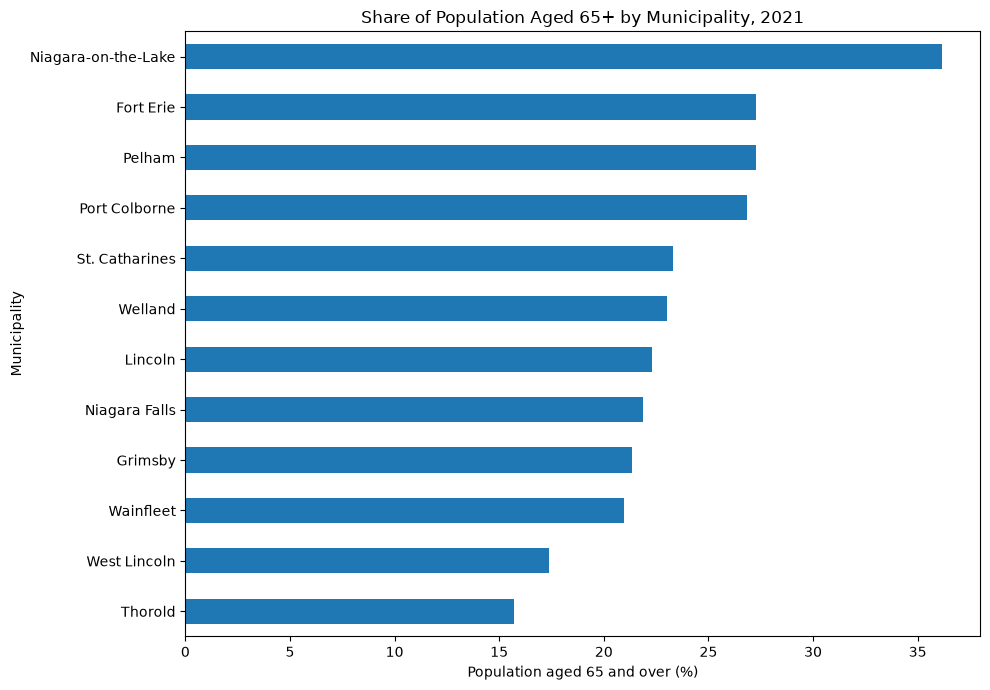

In [33]:
ax = older_2021.sort_values("share_65_plus_pct").plot(
    x=GEO, y="share_65_plus_pct", kind="barh", legend=False, figsize=(10, 7)
)
ax.set_title("Share of Population Aged 65+ by Municipality, 2021")
ax.set_xlabel("Population aged 65 and over (%)")
ax.set_ylabel("Municipality")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "municipality_share_age_65_plus_2021.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Median age by municipality

Median age is taken from the dedicated `Median age` record. These are population-level medians, not business-owner ages.


In [34]:
median_age = df.loc[
    df[GEO].isin(municipalities) & df[AGE].eq("Median age"),
    [GEO, YEAR, POP]
].rename(columns={POP: "median_age"})

assert not median_age.duplicated([GEO, YEAR]).any(), "Duplicate median-age records found."
median_pivot = median_age.pivot(index=GEO, columns=YEAR, values="median_age")

median_pivot["change_2016_to_2021"] = median_pivot[2021] - median_pivot[2016]
median_pivot = median_pivot.sort_values(2021, ascending=True)
display(median_pivot)


Census year (2),2016,2021,change_2016_to_2021
GEO,,,
Thorold,41.2,37.2,-4.0
West Lincoln,40.4,40.8,0.4
Lincoln,44.4,44.4,0.0
Niagara Falls,44.8,44.8,0.0
St. Catharines,44.8,44.8,0.0
Welland,45.6,45.2,-0.4
Grimsby,43.6,45.2,1.6
Wainfleet,46.8,47.2,0.4
Pelham,49.6,50.4,0.8


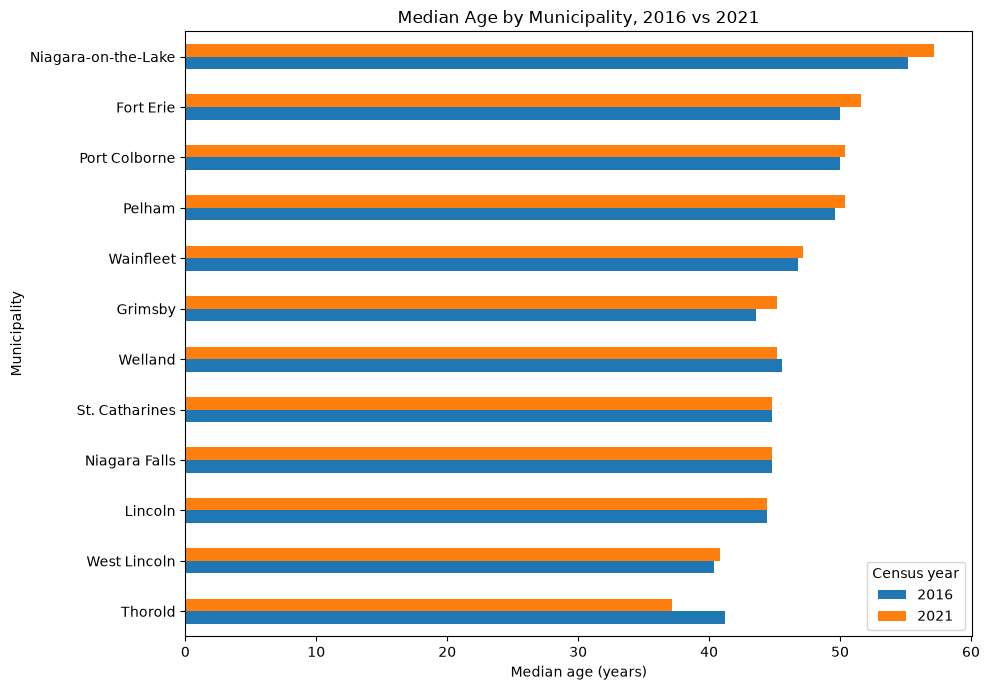

In [35]:
ax = median_pivot[[2016, 2021]].plot(
    kind="barh", figsize=(10, 7)
)
ax.set_title("Median Age by Municipality, 2016 vs 2021")
ax.set_xlabel("Median age (years)")
ax.set_ylabel("Municipality")
ax.legend(title="Census year")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "municipality_median_age_2016_2021.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Evidence-based findings

In [36]:
# Generate summary metrics directly from the analysis tables.
print("FINDING 1 ? Niagara population change")
print(f"2016 population: {population_2016:,.0f}")
print(f"2021 population: {population_2021:,.0f}")
print(f"Absolute change: {absolute_change:,.0f}")
print(f"Percentage change: {percent_change:.2f}%")

print("\nFINDING 2 ? Highest 65+ population shares in 2021")
display(
    older_2021[[GEO, "population_65_plus", "total_population", "share_65_plus_pct"]]
    .head(5).reset_index(drop=True)
)

print("\nFINDING 3 ? Median-age change from 2016 to 2021")
print("Largest increases:")
display(median_pivot.sort_values("change_2016_to_2021", ascending=False).head(5))
print("Smallest increases / decreases:")
display(median_pivot.sort_values("change_2016_to_2021").head(5))

# Compare the two broad age groups most relevant to population ageing.
age_summary = age_structure.pivot(
    index="age_group", columns=YEAR, values="percentage"
)
print("\nAge-group share change (percentage points), 2016 to 2021:")
age_summary["change_pp"] = age_summary[2021] - age_summary[2016]
display(age_summary)


FINDING 1 ? Niagara population change
2016 population: 447,890
2021 population: 477,940
Absolute change: 30,050
Percentage change: 6.71%

FINDING 2 ? Highest 65+ population shares in 2021


,GEO,population_65_plus,total_population,share_65_plus_pct
0,Niagara-on-the-Lake,6905.0,19090.0,36.170770
1,Fort Erie,8970.0,32900.0,27.264438
2,Pelham,4960.0,18195.0,27.260236
3,Port Colborne,5375.0,20035.0,26.828051
4,St. Catharines,31865.0,136800.0,23.293129



FINDING 3 ? Median-age change from 2016 to 2021
Largest increases:


Census year (2),2016,2021,change_2016_to_2021
GEO,,,
Niagara-on-the-Lake,55.2,57.2,2.0
Grimsby,43.6,45.2,1.6
Fort Erie,50.0,51.6,1.6
Pelham,49.6,50.4,0.8
Wainfleet,46.8,47.2,0.4


Smallest increases / decreases:


Census year (2),2016,2021,change_2016_to_2021
GEO,,,
Thorold,41.2,37.2,-4.0
Welland,45.6,45.2,-0.4
Niagara Falls,44.8,44.8,0.0
Lincoln,44.4,44.4,0.0
St. Catharines,44.8,44.8,0.0



Age-group share change (percentage points), 2016 to 2021:


Census year (2),2016,2021,change_pp
age_group,,,
0–14,14.905446,14.770683,-0.134763
15–24,12.027507,10.987781,-1.039726
25–34,10.968095,12.003599,1.035504
35–44,11.185782,11.321505,0.135723
45–54,14.394159,12.263046,-2.131114
55–64,15.117551,15.359669,0.242117
65–74,11.788609,13.068586,1.279977
75–84,6.474804,7.123279,0.648475
85+,3.132466,3.108131,-0.024335


## 8. Limitations and interpretation

1. **Demographic proxy:** Population age does not identify business owners or their succession plans.
2. **Two time points:** 2016 and 2021 show change between two census snapshots, not a continuous trend.
3. **Geographic aggregation:** Municipality-level patterns may conceal variation within each municipality.
4. **Age-category hierarchy:** Census age tables include overlapping totals and subcategories. This analysis uses single-year ages for age structure and direct published records for 65+ and median age.
5. **Source fields:** `REF_DATE` is 2021 for all rows, while `Census year (2)` identifies the two census observation years. The latter is used for comparisons.
6. **Scope:** This is exploratory analysis. It does not estimate succession risk, predict business closures, or establish causation.

## 9. Outputs

Figures are saved to `reports/figures/`:
- `niagara_age_structure_2016_2021.png`
- `municipality_share_age_65_plus_2021.png`
- `municipality_median_age_2016_2021.png`

The numeric tables and findings above should be reviewed before they are used in the Week 5 written report.


**Data validation note:** Detailed age-group counts differ slightly from the published regional totals: −25 in 2016 and +30 in 2021. Raw and cleaned age-category counts match, so no discrepancies were introduced during cleaning. The cause remains unconfirmed, and no values were adjusted.
